# 01 · Análisis exploratorio
**Pregunta del proyecto:** *antes de llamar* a un cliente, ¿aceptará abrir un depósito a plazo?

Solo usamos variables disponibles **antes de la llamada**. La duración de la llamada queda fuera del modelo porque solo se conoce cuando la llamada ya terminó (fuga de datos).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222, archivo bank-additional-full.csv), copia pública en GitHub.
# Plan B: descarguen bank-additional-full.csv desde UCI y súbanlo al panel Archivos de Colab.
URL = "https://raw.githubusercontent.com/selva86/datasets/master/bank-full.csv"

NOMBRES = {
    "age": "edad", "job": "ocupacion", "marital": "estado_civil", "education": "educacion",
    "default": "en_mora", "housing": "hipoteca", "loan": "prestamo", "contact": "tipo_contacto",
    "month": "mes", "day_of_week": "dia_semana", "duration": "duracion_llamada",
    "campaign": "contactos_campana", "pdays": "dias_ultimo_contacto", "previous": "contactos_previos",
    "poutcome": "resultado_previo", "emp.var.rate": "tasa_var_empleo", "cons.price.idx": "ipc",
    "cons.conf.idx": "confianza_consumidor", "euribor3m": "euribor3m", "nr.employed": "num_empleados"}

NUMERICAS = ["edad", "contactos_campana", "dias_ultimo_contacto", "contactos_previos",
             "tasa_var_empleo", "ipc", "confianza_consumidor", "euribor3m", "num_empleados"]
CATEGORICAS = ["ocupacion", "estado_civil", "educacion", "en_mora", "hipoteca", "prestamo",
               "tipo_contacto", "mes", "dia_semana", "resultado_previo"]
# duracion_llamada NO entra al modelo: solo se conoce DESPUÉS de la llamada (fuga de datos).

def cargar_datos():
    try:
        df = pd.read_csv(URL, sep=";")
    except Exception:
        df = pd.read_csv("bank-additional-full.csv", sep=";")
    df = df.rename(columns=NOMBRES)
    # 999 significa "nunca fue contactado": no es una cantidad, lo convertimos en faltante
    df["dias_ultimo_contacto"] = df["dias_ultimo_contacto"].replace(999, np.nan)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df.drop(columns="y")

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(41188, 21) | suscriben: 11.3%


## ¿Cuántos suscriben?

suscribe
no suscribe    36548
suscribe        4640
Name: count, dtype: int64


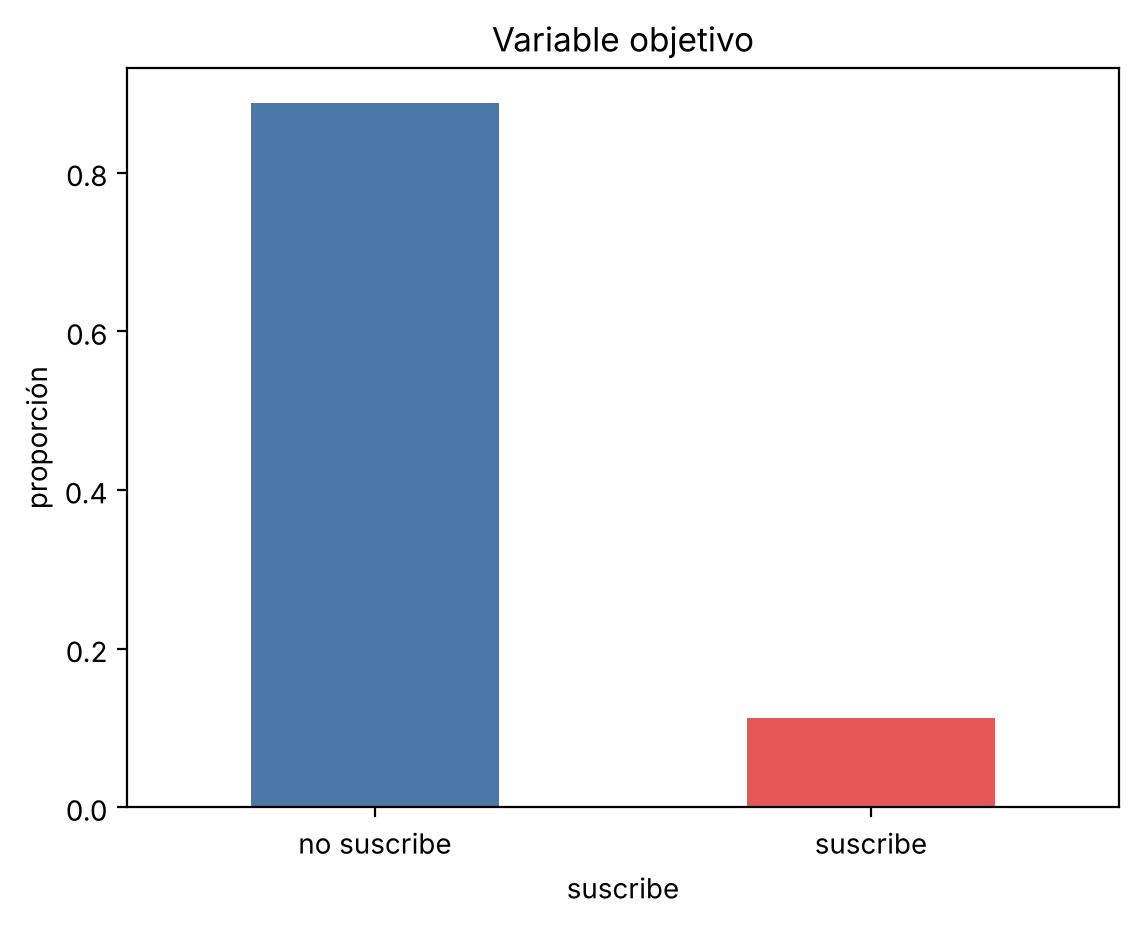

In [2]:
print(y.value_counts().rename({0: "no suscribe", 1: "suscribe"}))
y.value_counts(normalize=True).rename({0: "no suscribe", 1: "suscribe"}).plot.bar(color=["#4C78A8", "#E45756"])
plt.ylabel("proporción"); plt.title("Variable objetivo"); plt.xticks(rotation=0); plt.show()

## Valores faltantes y desconocidos
El archivo no tiene celdas vacías, pero sí la etiqueta `unknown` y el código 999 (nunca contactado).

In [3]:
print("Faltantes (NaN):"); print(df[NUMERICAS].isna().mean().loc[lambda s: s > 0].map("{:.1%}".format))
print("\nValores 'unknown':"); print((df[CATEGORICAS] == "unknown").mean().loc[lambda s: s > 0].map("{:.1%}".format))

Faltantes (NaN):
dias_ultimo_contacto    96.3%
dtype: str

Valores 'unknown':
ocupacion        0.8%
estado_civil     0.2%
educacion        4.2%
en_mora         20.9%
hipoteca         2.4%
prestamo         2.4%
dtype: str


## Hallazgo 1 · El resultado de la campaña anterior

In [4]:
t = df.groupby("resultado_previo")["suscribe"].agg(["mean", "size"])
t["mean"] = (t["mean"] * 100).round(0).astype(int).astype(str) + " %"
t.columns = ["tasa de suscripción", "clientes"]; t

,tasa de suscripción,clientes
resultado_previo,,
failure,14 %,4252
nonexistent,9 %,35563
success,65 %,1373


## Hallazgo 2 · El contexto económico (tasa euribor a 3 meses)

euribor3m
< 1 %    46 %
1–2 %    16 %
2–4 %     7 %
> 4 %     5 %
Name: suscribe, dtype: str


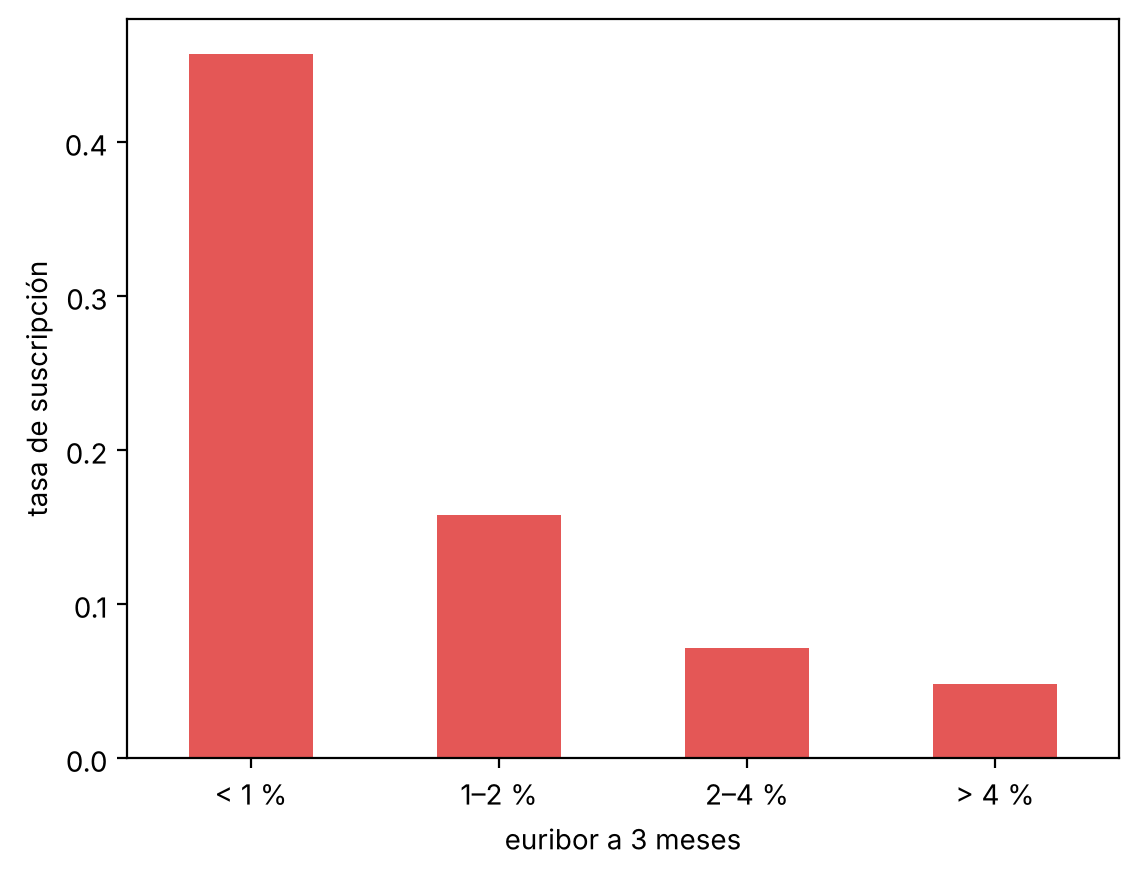

In [5]:
tramos = pd.cut(df["euribor3m"], [0, 1, 2, 4, 6], labels=["< 1 %", "1–2 %", "2–4 %", "> 4 %"])
tasa = df.groupby(tramos, observed=True)["suscribe"].mean()
print((tasa * 100).round(0).astype(int).astype(str) + " %")
tasa.plot.bar(color="#E45756"); plt.ylabel("tasa de suscripción"); plt.xlabel("euribor a 3 meses")
plt.xticks(rotation=0); plt.show()

## Hallazgo 3 · Insistir no funciona: número de llamadas en esta campaña

contactos_campana
1       13.0 %
2       11.5 %
3       10.7 %
4–5      8.7 %
6–10     6.3 %
> 10     3.1 %
Name: suscribe, dtype: str


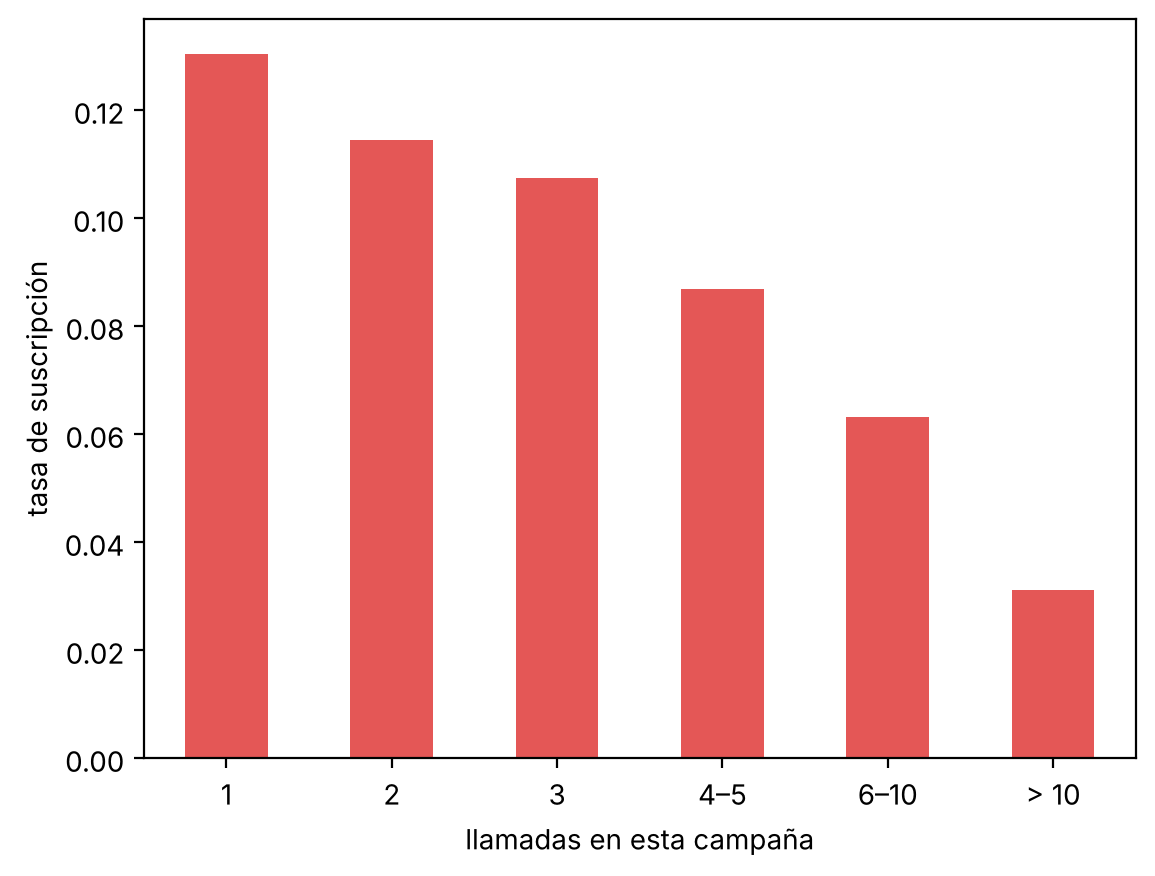

In [6]:
tramos = pd.cut(df["contactos_campana"], [0, 1, 2, 3, 5, 10, 100], labels=["1", "2", "3", "4–5", "6–10", "> 10"])
tasa = df.groupby(tramos, observed=True)["suscribe"].mean()
print((tasa * 100).round(1).astype(str) + " %")
tasa.plot.bar(color="#E45756"); plt.ylabel("tasa de suscripción"); plt.xlabel("llamadas en esta campaña")
plt.xticks(rotation=0); plt.show()

## Hallazgo 4 · La edad: jóvenes y mayores suscriben más

In [7]:
tramos_edad = pd.cut(df["edad"], [0, 25, 30, 45, 60, 100], labels=["≤ 25", "26–30", "31–45", "46–60", "> 60"])
print((df.groupby(tramos_edad, observed=True)["suscribe"].mean() * 100).round(0).astype(int).astype(str) + " %")

edad
≤ 25     21 %
26–30    14 %
31–45     9 %
46–60    10 %
> 60     45 %
Name: suscribe, dtype: str


## Hallazgo 5 · La variable tramposa: duración de la llamada

In [8]:
tramos = pd.qcut(df["duracion_llamada"], 5, labels=["muy corta", "corta", "media", "larga", "muy larga"])
print((df.groupby(tramos, observed=True)["suscribe"].mean() * 100).round(0).astype(int).astype(str) + " %")
print("\nLlamadas de 0 segundos:", (df["duracion_llamada"] == 0).sum(), "→ tasa de suscripción:",
      df.loc[df["duracion_llamada"] == 0, "suscribe"].mean())

duracion_llamada
muy corta     1 %
corta         3 %
media         7 %
larga        12 %
muy larga    33 %
Name: suscribe, dtype: str

Llamadas de 0 segundos: 4 → tasa de suscripción: 0.0


## Hallazgos principales
1. **Clases muy desbalanceadas:** solo ~11 % suscribe. Un modelo que diga siempre "no" tendría ~89 % de accuracy, así que **no usaremos la accuracy**.
2. **El historial manda:** los clientes que aceptaron en la campaña anterior suscriben en ~65 %, contra ~9 % de los que nunca fueron contactados.
3. **El contexto económico pesa mucho:** con euribor bajo (< 1 %) la tasa de suscripción es varias veces mayor que con euribor alto (> 4 %).
4. **Insistir no ayuda:** la tasa cae a medida que aumentan las llamadas en la misma campaña.
5. **La duración de la llamada predice casi perfecto, pero es fuga de datos:** solo se conoce *después* de llamar. La excluimos del modelo.